In [1]:
#Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import classification_report
import seaborn as sns
from sklearn.metrics import confusion_matrix


In [2]:
# To Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [3]:
#Load dataset
data = "data.txt"
df1 = pd.read_csv(data, delim_whitespace=True)


In [4]:
print(df1.head())

         Date             Time  Epoch  MoteID  Temperature  Humidity  Light  \
0  2004-03-31  03:38:15.757551      2     1.0     122.1530  -3.91901  11.04   
1  2004-02-28   00:59:16.02785      3     1.0      19.9884  37.09330  45.08   
2  2004-02-28   01:03:16.33393     11     1.0      19.3024  38.46290  45.08   
3  2004-02-28  01:06:16.013453     17     1.0      19.1652  38.80390  45.08   
4  2004-02-28  01:06:46.778088     18     1.0      19.1750  38.83790  45.08   

   Voltage  
0  2.03397  
1  2.69964  
2  2.68742  
3  2.68742  
4  2.69964  


In [5]:
# Handle missing values using Forward Fill (FFill)
df1.fillna(method='ffill', inplace=True)

## Creating Anomaly Column

In [6]:
# Creating Anomaly Columns by detecting anomaly
def detect_anomaly(row):
    if row['Temperature'] > 100 or row['Temperature'] < -20:
        return 1
    if row['Humidity'] < 0 or row['Humidity'] > 100:
        return 1
    if row['Voltage'] < 2.1:
        return 1
    return 0

df1['anomaly_label'] = df1.apply(detect_anomaly, axis=1)


In [7]:
print(df1.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2313682 entries, 0 to 2313681
Data columns (total 9 columns):
 #   Column         Dtype  
---  ------         -----  
 0   Date           object 
 1   Time           object 
 2   Epoch          int64  
 3   MoteID         float64
 4   Temperature    float64
 5   Humidity       float64
 6   Light          float64
 7   Voltage        float64
 8   anomaly_label  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 158.9+ MB
None


## Features Selection

In [8]:
# Feature selection - Selecting relevant sensor readings
features = ["Temperature", "Humidity", "Light", "Voltage"]
target = "anomaly_label"


In [9]:
print(df1.describe())

              Epoch        MoteID   Temperature      Humidity         Light  \
count  2.313682e+06  2.313682e+06  2.313682e+06  2.313682e+06  2.313682e+06   
mean   3.303993e+04  4.340747e+01  3.925901e+01  3.390085e+01  3.912469e+02   
std    1.836852e+04  9.869573e+02  3.761196e+01  1.732670e+01  5.347266e+02   
min    0.000000e+00  1.000000e+00 -3.840000e+01 -8.983130e+03  0.000000e+00   
25%    1.757200e+04  1.700000e+01  2.040980e+01  3.187760e+01  1.840000e+01   
50%    3.332700e+04  2.900000e+01  2.243840e+01  3.928030e+01  1.435200e+02   
75%    4.778900e+04  4.100000e+01  2.702480e+01  4.358550e+01  5.078400e+02   
max    6.553500e+04  6.540700e+04  3.855680e+02  1.375120e+02  1.847360e+03   

            Voltage  anomaly_label  
count  2.313682e+06   2.313682e+06  
mean   2.486267e+00   1.707274e-01  
std    1.782132e-01   3.762707e-01  
min    9.100830e-03   0.000000e+00  
25%    2.366220e+00   0.000000e+00  
50%    2.516610e+00   0.000000e+00  
75%    2.627960e+00   0.00000

Data Cleaning and Preprocessing

In [10]:
#checking for missing data 
df1.isnull().sum() 

Date             0
Time             0
Epoch            0
MoteID           0
Temperature      0
Humidity         0
Light            0
Voltage          0
anomaly_label    0
dtype: int64

In [11]:
# Handle missing values using Forward Fill (FFill)
df1.fillna(method='ffill', inplace=True)

In [12]:
#Check if there are any duplicate rows in the datasets:
print(df1.duplicated().sum())

0


In [13]:
# Droping duplicates
Cleaned_data = df1.drop_duplicates()

## Data Training and Testing with Random Forest Model

In [14]:
from sklearn.ensemble import RandomForestClassifier

Splitting the Data

In [15]:
# Splitting data into features (X) and target (y)
X1 = Cleaned_data[features]
y1 = Cleaned_data[target]

In [16]:
# Normalize the feature data
scaler = StandardScaler()
X1_scaled = scaler.fit_transform(X1)

In [17]:
# Split dataset into 80% training and 20% testing
X1_train, X1_test, y1_train, y1_test = train_test_split(X1_scaled, y1, test_size=0.2, random_state=42)

In [18]:
# Initialize the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)

In [19]:

# Train the model
rf_model.fit(X1_train, y1_train)


RandomForestClassifier(max_depth=10, random_state=42)

In [20]:
# Make predictions on the test set
y1_pred = rf_model.predict(X1_test)

In [21]:
# Evaluate model performance
accuracy_rf = accuracy_score(y1_test, y1_pred)
precision_rf = precision_score(y1_test, y1_pred)
recall_rf = recall_score(y1_test, y1_pred)
f1_rf = f1_score(y1_test, y1_pred)
roc_auc_rf = roc_auc_score(y1_test, y1_pred)


In [22]:
# Confusion Matrix
cm_rf = confusion_matrix(y1_test, y1_pred)

# Classification Report
report_rf = classification_report(y1_test, y1_pred)

In [23]:
#Print evaluation metrics
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1 Score: {f1_rf:.4f}")
print(f"ROC-AUC Score: {roc_auc_rf:.4f}")


Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
ROC-AUC Score: 1.0000


In [24]:
print("Confusion Matrix:")
print(cm_rf)
print("\n")
# Classification Report
report_rf = classification_report(y1_test, y1_pred)
print("Classification Report:")
print(report_rf)

Confusion Matrix:
[[383852      0]
 [     0  78885]]


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    383852
           1       1.00      1.00      1.00     78885

    accuracy                           1.00    462737
   macro avg       1.00      1.00      1.00    462737
weighted avg       1.00      1.00      1.00    462737



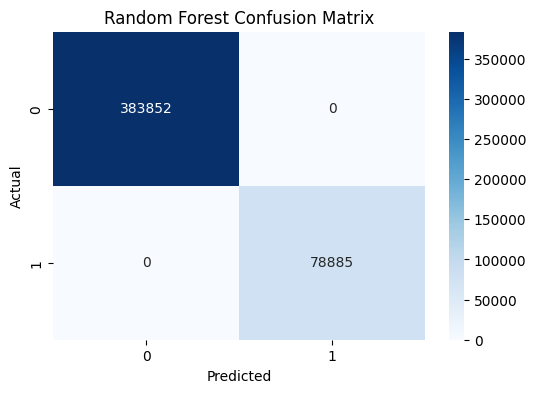

In [27]:
import matplotlib.pyplot as plt

# Compute the confusion matrix
cm_rf = confusion_matrix(y1_test, rf_model.predict(X1_test))

# Plot the heatmap
plt.figure(figsize=(6, 4))
ax1 = sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')

# Add labels and title
ax1.set_title('Random Forest Confusion Matrix')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

# Show the plot
plt.show()


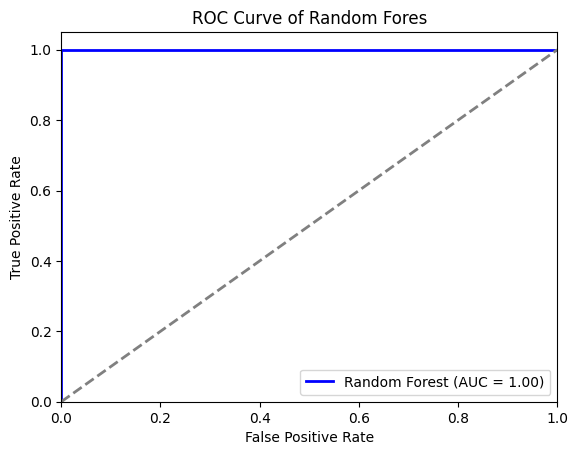

In [102]:
# Plot ROC curves of Random Forest
plt.figure()
plt.plot(fpr_rf, tpr_rf, color='blue', lw=2, label=f'Random Forest (AUC = {auc_rf:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve of Random Fores')
plt.legend(loc="lower right")
plt.show()

## Data Training and Testing with Extra Trees Model

In [28]:
# Import ExtraTreesClassifier
from sklearn.ensemble import ExtraTreesClassifier

In [29]:
# Splitting data into features (X) and target (y)
X2 = Cleaned_data[features]
y2 = Cleaned_data[target]

# Normalize the feature data
scaler = StandardScaler()
X2_scaled = scaler.fit_transform(X2)


In [30]:
# Split dataset into 80% training, and 20% test sets
X2_train, X2_test, y2_train, y2_test = train_test_split(X2_scaled, y2, test_size=0.2, random_state=42)

In [31]:
# Initialize the Extra Trees model
et_model = ExtraTreesClassifier(n_estimators=100, max_depth=10, random_state=42)

# Train the model
et_model.fit(X2_train, y2_train)


ExtraTreesClassifier(max_depth=10, random_state=42)

In [32]:
# Make predictions on the test set
y2_pred = et_model.predict(X2_test)

In [33]:
# Evaluate model performance
accuracy_et = accuracy_score(y2_test, y2_pred)
precision_et = precision_score(y2_test, y2_pred)
recall_et = recall_score(y2_test, y2_pred)
f1_et = f1_score(y2_test, y2_pred)
roc_auc_et = roc_auc_score(y2_test, y2_pred)

In [34]:
# Confusion Matrix
cm_et = confusion_matrix(y2_test, y2_pred)

# Classification Report
report_et = classification_report(y2_test, y2_pred)

In [35]:
# Print evaluation metrics
print(f"Accuracy: {accuracy_et:.4f}")
print(f"Precision: {precision_et:.4f}")
print(f"Recall: {recall_et:.4f}")
print(f"F1 Score: {f1_et:.4f}")
print(f"ROC-AUC Score: {roc_auc_et:.4f}")

Accuracy: 0.9994
Precision: 0.9998
Recall: 0.9965
F1 Score: 0.9981
ROC-AUC Score: 0.9982


In [36]:
print("Confusion Matrix:")
print(cm_et)
print("\n")
# Classification Report
report_et = classification_report(y2_test, y2_pred)
print("Classification Report:")
print(report_et)

Confusion Matrix:
[[383833     19]
 [   274  78611]]


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    383852
           1       1.00      1.00      1.00     78885

    accuracy                           1.00    462737
   macro avg       1.00      1.00      1.00    462737
weighted avg       1.00      1.00      1.00    462737



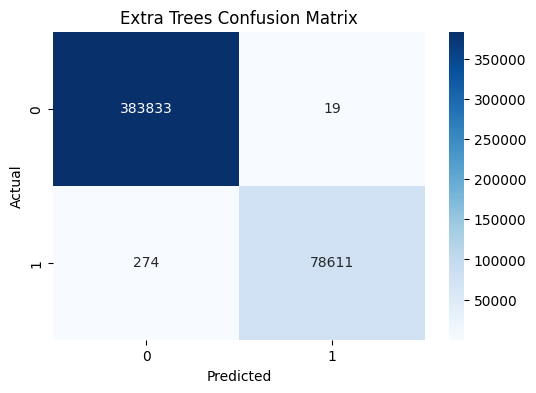

In [37]:
# Compute the confusion matrix
cm_et = confusion_matrix(y2_test, et_model.predict(X2_test))

# Plot the heatmap
plt.figure(figsize=(6, 4))
ax2 = sns.heatmap(cm_et, annot=True, fmt='d', cmap='Blues')

# Add labels and title
ax2.set_title('Extra Trees Confusion Matrix')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')

# Show the plot
plt.show()


Extra Trees Confusion Matrix Map

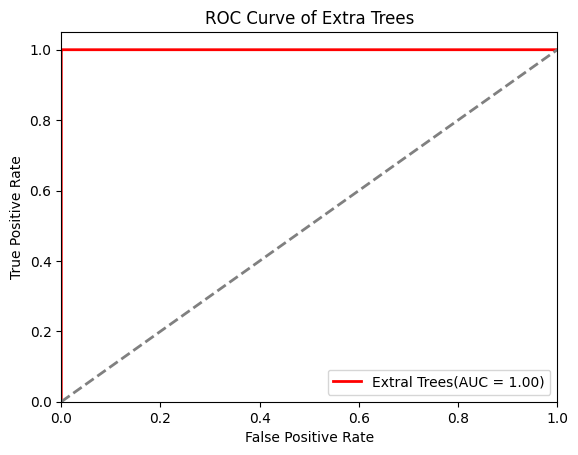

In [107]:
# Plot ROC curves of Extra Trees
plt.figure()
plt.plot(fpr_et, tpr_et, color='red', lw=2, label=f'Extral Trees(AUC = {auc_et:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve of Extra Trees')
plt.legend(loc="lower right")
plt.show()

## Data Training and Testing with XGBoost Model

In [38]:
# Import xgboost
import xgboost as xgb
from xgboost import XGBClassifier


In [39]:

# Display first few rows of the dataset
print(Cleaned_data.head())

         Date             Time  Epoch  MoteID  Temperature  Humidity  Light  \
0  2004-03-31  03:38:15.757551      2     1.0     122.1530  -3.91901  11.04   
1  2004-02-28   00:59:16.02785      3     1.0      19.9884  37.09330  45.08   
2  2004-02-28   01:03:16.33393     11     1.0      19.3024  38.46290  45.08   
3  2004-02-28  01:06:16.013453     17     1.0      19.1652  38.80390  45.08   
4  2004-02-28  01:06:46.778088     18     1.0      19.1750  38.83790  45.08   

   Voltage  anomaly_label  
0  2.03397              1  
1  2.69964              0  
2  2.68742              0  
3  2.68742              0  
4  2.69964              0  


In [40]:
# Splitting data into features (X) and target (y)
X3 = Cleaned_data[features]
y3 = Cleaned_data[target]

In [41]:
# Normalize the feature data
scaler = StandardScaler()
X3_scaled = scaler.fit_transform(X3)

In [42]:

# Split dataset into 80% training, and 20% test sets
X3_train, X3_test, y3_train, y3_test = train_test_split(X3_scaled, y3, test_size=0.2, random_state=42)


# Convert datasets into DMatrix format for XGBoost
dtrain_xgb = xgb.DMatrix(X3_train, label=y3_train)
dtest = xgb.DMatrix(X3_test)


In [43]:
# Define XGBoost parameters
params_xgb = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'eta': 0.1,
    'max_depth': 6,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'random_state': 42
}


In [44]:
# Train the XGB model
xgb_model = xgb.train(
    params=params_xgb,
    dtrain=dtrain_xgb,
    num_boost_round=200,
    verbose_eval=True
)

In [45]:

# Make predictions on the test set
y3_pred_prob = xgb_model.predict(dtest)
y3_pred = np.where(y3_pred_prob > 0.5, 1, 0)  # Convert probabilities to binary class labels

In [46]:
# Evaluate model performance
accuracy_xgb = accuracy_score(y3_test, y3_pred)
precision_xgb = precision_score(y3_test, y3_pred)
recall_xgb = recall_score(y3_test, y3_pred)
f1_xgb = f1_score(y3_test, y3_pred)
roc_auc_xgb = roc_auc_score(y3_test, y3_pred_prob)

In [47]:
# Confusion Matrix
cm_xgb = confusion_matrix(y3_test, y3_pred)

# Classification Report
report_xgb = classification_report(y3_test, y3_pred)

In [48]:

# Print evaluation metrics
print(f"Accuracy: {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall: {recall_xgb:.4f}")
print(f"F1 Score: {f1_xgb:.4f}")
print(f"ROC-AUC Score: {roc_auc_xgb:.4f}")

Accuracy: 0.9995
Precision: 0.9985
Recall: 0.9988
F1 Score: 0.9987
ROC-AUC Score: 1.0000


In [49]:
print("Confusion Matrix:")
print(cm_xgb)
print("\n")
# Classification Report
report_xgb = classification_report(y3_test, y3_pred)
print("Classification Report:")
print(report_xgb)

Confusion Matrix:
[[383737    115]
 [    97  78788]]


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    383852
           1       1.00      1.00      1.00     78885

    accuracy                           1.00    462737
   macro avg       1.00      1.00      1.00    462737
weighted avg       1.00      1.00      1.00    462737



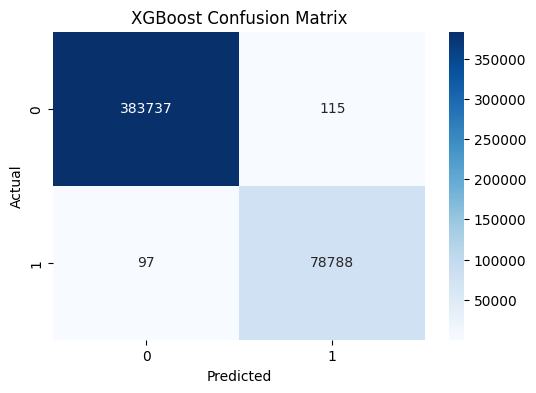

In [57]:
# Convert test set to DMatrix
dtest_xgb = xgb.DMatrix(X3_test)

# Make predictions
predictions_xgb = xgb_model.predict(dtest_xgb)
predictions_xgb = (predictions_xgb > 0.5).astype(int)

# Compute the confusion matrix
cm_xgb = confusion_matrix(y3_test, predictions_xgb)

# Plot the heatmap
plt.figure(figsize=(6, 4))
ax3 = sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues')

# Add labels and title
ax3.set_title('XGBoost Confusion Matrix')
ax3.set_xlabel('Predicted')
ax3.set_ylabel('Actual')

# Show the plot
plt.show()


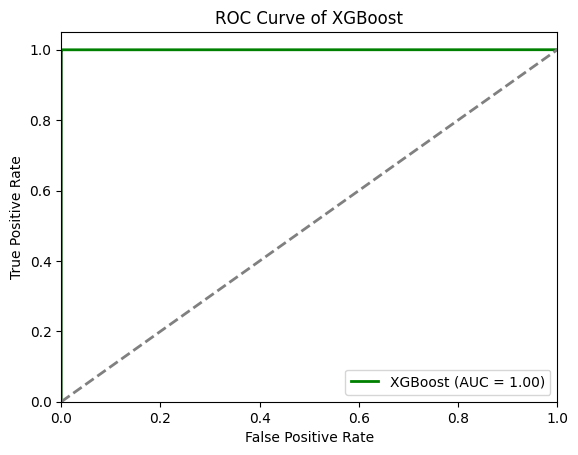

In [104]:
# Plot ROC curves of XGBoost
plt.figure()
plt.plot(fpr_xgb, tpr_xgb, color='green', lw=2, label=f'XGBoost (AUC = {auc_xgb:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve of XGBoost')
plt.legend(loc="lower right")
plt.show()

## Data Training and Testing with LightGBM Model

In [58]:
# Import the lgb model
import lightgbm as lgb


In [59]:
# Feature selection - Selecting relevant sensor readings
features = ["Temperature", "Humidity", "Light", "Voltage"]
target = "anomaly_label"  # Ensure the dataset includes an anomaly label

In [60]:
# Splitting data into features (X) and target (y)
X4 = Cleaned_data[features]
y4 = Cleaned_data[target]

# Normalize the feature data
scaler = StandardScaler()
X4_scaled = scaler.fit_transform(X4)


In [61]:
# Split dataset into 80% training, and 20% test sets
X4_train, X4_test, y4_train, y4_test = train_test_split(X4_scaled, y4, test_size=0.2, random_state=42)

In [62]:
# Convert datasets into LightGBM Dataset format
dtrain_lgb = lgb.Dataset(X4_train, label=y4_train)

In [63]:
# Define LightGBM parameters
params_lgb = {
    'objective': 'binary',
    'metric': 'binary_logloss',
    'verbosity': 1,     # Controls logging (0 = silent, 1 = info, >1 = debug)
    'learning_rate': 0.1,
    'max_depth': 6,
    'num_leaves': 31,
    'random_state': 42
}

In [64]:
lgb_model = lgb.train(
    params=params_lgb,
    train_set=dtrain_lgb,
    num_boost_round=200
)

[LightGBM] [Info] Number of positive: 316124, number of negative: 1534821
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.038721 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 783
[LightGBM] [Info] Number of data points in the train set: 1850945, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.170791 -> initscore=-1.580034
[LightGBM] [Info] Start training from score -1.580034
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

In [65]:
# Make predictions on the test set
y4_pred_prob = lgb_model.predict(X4_test)
y4_pred = np.where(y4_pred_prob > 0.5, 1, 0)  # Convert probabilities to binary class labels


In [66]:
# Evaluate model performance
accuracy_lgb = accuracy_score(y4_test, y4_pred)
precision_lgb = precision_score(y4_test, y4_pred)
recall_lgb = recall_score(y4_test, y4_pred)
f1_lgb = f1_score(y4_test, y4_pred)
roc_auc_lgb = roc_auc_score(y4_test, y4_pred_prob)


In [67]:
# Confusion Matrix
cm_lgb = confusion_matrix(y4_test, y4_pred)

# Classification Report
report_lgb = classification_report(y4_test, y4_pred)

In [68]:
# Print evaluation metrics
print(f"Accuracy: {accuracy_lgb:.4f}")
print(f"Precision: {precision_lgb:.4f}")
print(f"Recall: {recall_lgb:.4f}")
print(f"F1 Score: {f1_lgb:.4f}")
print(f"ROC-AUC Score: {roc_auc_lgb:.4f}")


Accuracy: 0.9999
Precision: 0.9998
Recall: 0.9994
F1 Score: 0.9996
ROC-AUC Score: 1.0000


In [69]:
print("Confusion Matrix:")
print(cm_lgb)
print("\n")
# Classification Report
report_rf = classification_report(y4_test, y4_pred)
print("Classification Report:")
print(report_lgb)

Confusion Matrix:
[[383835     17]
 [    51  78834]]


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    383852
           1       1.00      1.00      1.00     78885

    accuracy                           1.00    462737
   macro avg       1.00      1.00      1.00    462737
weighted avg       1.00      1.00      1.00    462737



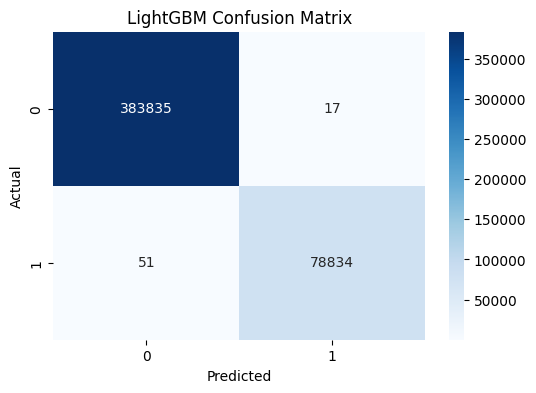

In [72]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Make predictions (LGBMClassifier returns probabilities by default)
predictions_lgb = lgb_model.predict(X4_test)
predictions_lgb = (predictions_lgb > 0.5).astype(int)

# Compute the confusion matrix
cm_lgb = confusion_matrix(y4_test, predictions_lgb)

# Plot the heatmap
plt.figure(figsize=(6, 4))
ax4 = sns.heatmap(cm_lgb, annot=True, fmt='d', cmap='Blues')

# Add labels and title
ax4.set_title('LightGBM Confusion Matrix')  # Fixed title from 'XGBoost'
ax4.set_xlabel('Predicted')
ax4.set_ylabel('Actual')

# Show the plot
plt.show()


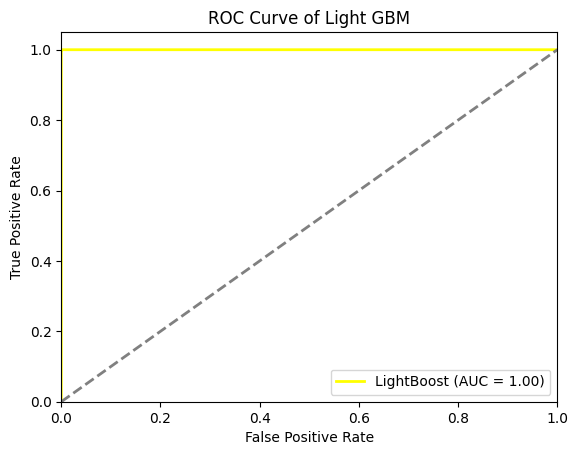

In [106]:
# Plot ROC curves of LightGBM
plt.figure()
plt.plot(fpr_lgb, tpr_lgb, color='yellow', lw=2, label=f'LightBoost (AUC = {auc_lgb:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve of Light GBM')
plt.legend(loc="lower right")
plt.show()

## Ensemble Model

Collect Predictions from Each Model
After training, collect the predictions made by each model on the test dataset.

In [73]:
# Convert test set to DMatrix
dtest_xgb = xgb.DMatrix(X3_test)

In [74]:
predictions_lgb = (lgb_model.predict(X4_test) > 0.5).astype(int)

In [75]:
# Predictions from Fandom Forest
predictions_rf = rf_model.predict(X1_test)

# Predictions from Extral Trees
predictions_et = et_model.predict(X2_test)

# Predictions from XGBoost
# Make predictions
predictions_xgb = xgb_model.predict(dtest_xgb)
# Convert probabilities to binary labels (if it's a classification task)
predictions_xgb = (predictions_xgb > 0.5).astype(int)

# Predictions from LightBoost
predictions_lgb = lgb_model.predict(X4_test)
predictions_lgb = (predictions_lgb > 0.5).astype(int)

In [76]:
# Accuracy
accuracy_rf = accuracy_score(y1_test, predictions_rf)
accuracy_et = accuracy_score(y2_test, predictions_et)
accuracy_xgb = accuracy_score(y3_test, predictions_xgb)
accuracy_lgb = accuracy_score(y4_test, predictions_lgb)

# Confusion Matrix
cm_rf = confusion_matrix(y1_test, predictions_rf)
cm_et = confusion_matrix(y2_test, predictions_et)
cm_xgb = confusion_matrix(y3_test, predictions_xgb)
cm_lgb = confusion_matrix(y4_test, predictions_lgb)

# Classification Report
report_rf = classification_report(y1_test, predictions_rf)
report_et = classification_report(y2_test, predictions_et)
report_xgb = classification_report(y3_test, predictions_xgb)
report_lgb = classification_report(y4_test, predictions_lgb)


In [77]:
print(f"Random Forest Accuracy: {accuracy_rf}")
print(f"Extral Trees Accuracy: {accuracy_et}")
print(f"XGBoost Accuracy: {accuracy_xgb}")
print(f"LightBoost Accuracy: {accuracy_lgb}")

print("\nRandom Forest Confusion Matrix:\n", cm_rf)
print("\Extral Trees Confusion Matrix:\n", cm_et)
print("\nXGBoost Confusion Matrix:\n", cm_xgb)
print("\nLightBoost Forest Confusion Matrix:\n", cm_lgb)

print("\nRandom Forest Classification Report:\n", report_rf)
print("\Extral Trees Classification Report:\n", report_et)
print("\nXGBoost Classification Report:\n", report_xgb)
print("\nLightBoost Classification Reportx:\n", report_lgb)

Random Forest Accuracy: 1.0
Extral Trees Accuracy: 0.99936681095309
XGBoost Accuracy: 0.9995418563892665
LightBoost Accuracy: 0.9998530482758025

Random Forest Confusion Matrix:
 [[383852      0]
 [     0  78885]]
\Extral Trees Confusion Matrix:
 [[383833     19]
 [   274  78611]]

XGBoost Confusion Matrix:
 [[383737    115]
 [    97  78788]]

LightBoost Forest Confusion Matrix:
 [[383835     17]
 [    51  78834]]

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    383852
           1       1.00      1.00      1.00     78885

    accuracy                           1.00    462737
   macro avg       1.00      1.00      1.00    462737
weighted avg       1.00      1.00      1.00    462737

\Extral Trees Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    383852
           1       1.00      1.00      1.00     78885

    accuracy  

Plot ROC Curves (Optional)
You can also compare the models using ROC curves and AUC (Area Under the Curve) scores. This is especially useful if your data is imbalanced.

In [78]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

In [79]:
# Calculate ROC curves
fpr_rf, tpr_rf, _ = roc_curve(y1_test, predictions_rf)
fpr_et, tpr_et, _ = roc_curve(y2_test, predictions_et)
fpr_xgb, tpr_xgb, _ = roc_curve(y3_test, predictions_xgb)
fpr_lgb,tpr_lgb, _ = roc_curve(y4_test, predictions_lgb)

In [80]:
# Calculate AUC
auc_rf = auc(fpr_rf, tpr_rf)
auc_et = auc(fpr_et, tpr_et)
auc_xgb = auc(fpr_xgb, tpr_xgb)
auc_lgb = auc(fpr_lgb, tpr_lgb) 


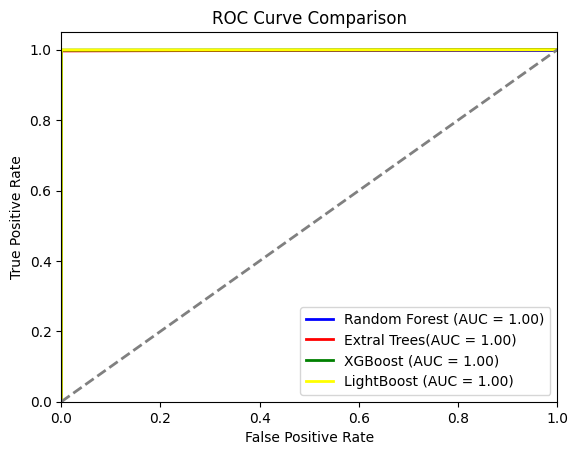

In [81]:
# Plot ROC curves
plt.figure()
plt.plot(fpr_rf, tpr_rf, color='blue', lw=2, label=f'Random Forest (AUC = {auc_rf:.2f})')
plt.plot(fpr_et, tpr_et, color='red', lw=2, label=f'Extral Trees(AUC = {auc_et:.2f})')
plt.plot(fpr_xgb, tpr_xgb, color='green', lw=2, label=f'XGBoost (AUC = {auc_xgb:.2f})')
plt.plot(fpr_lgb, tpr_lgb, color='yellow', lw=2, label=f'LightBoost (AUC = {auc_lgb:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc="lower right")
plt.show()

Compare the Results
After evaluating each model, compare the results based on the metrics you calculated.
You can create a summary table to organize and visualize the comparisons:

In [82]:
# Ensure your predictions are binary (0 or 1)
predictions_rf = (predictions_rf > 0.5).astype(int)
predictions_et = (predictions_et > 0.5).astype(int)
predictions_xgb = (predictions_xgb > 0.5).astype(int)  
predictions_lgb = (predictions_lgb > 0.5).astype(int) # Convert probabilities to binary if needed



# Calculating Metrics for Random Forest
accuracy_rf = accuracy_score(y1_test, predictions_rf)
precision_rf = precision_score(y1_test, predictions_rf)
recall_rf = recall_score(y1_test, predictions_rf)
f1_rf = f1_score(y1_test, predictions_rf)

# Assuming xgb_fpr and xgb_tpr were calculated earlier
auc_rf = auc(fpr_rf, tpr_rf)

# Calculating Metrics for Extral Trees
accuracy_et = accuracy_score(y2_test, predictions_et)
precision_et = precision_score(y2_test, predictions_et)
recall_et = recall_score(y2_test, predictions_et)
f1_et= f1_score(y2_test, predictions_et)

# Assuming xgb_fpr and xgb_tpr were calculated earlier
auc_et = auc(fpr_et, tpr_et)


# Calculating Metrics for XGBoost
accuracy_xgb = accuracy_score(y3_test, predictions_xgb)
precision_xgb = precision_score(y3_test, predictions_xgb)
recall_xgb = recall_score(y3_test, predictions_xgb)
f1_xgb = f1_score(y3_test, predictions_xgb)

# Assuming xgb_fpr and xgb_tpr were calculated earlier
auc_xgb = auc(fpr_xgb, tpr_xgb)

# Calculating Metrics for XGBoost
accuracy_lgb = accuracy_score(y4_test, predictions_lgb)
precision_lgb = precision_score(y4_test, predictions_lgb)
recall_lgb = recall_score(y4_test, predictions_lgb)
f1_lgb = f1_score(y4_test, predictions_lgb)

# Assuming xgb_fpr and xgb_tpr were calculated earlier
auc_lgb = auc(fpr_lgb, tpr_lgb)

# Displaying the results
print(f"Random Forest Accuracy: {accuracy_rf}")
print(f"Extral Trees Accuracy: {accuracy_et}")
print(f"XGBoost Accuracy: {accuracy_xgb}")
print(f"LightBoost Accuracy: {accuracy_lgb}")

print("\n")

print(f"Random Forest Precision: {precision_rf}")
print(f"Extral Trees Precision: {precision_et}")
print(f"XGBoost Precision: {precision_xgb}")
print(f"LightBoost Precision: {precision_lgb}")

print("\n")

print(f"Random Forest Recall: {recall_rf}")
print(f"Extral Trees Recall: {recall_et}")
print(f"XGBoost Recall: {recall_xgb}")
print(f"LightBoost Recall: {recall_lgb}")

print("\n")

print(f"Random Forest F1-Score: {f1_rf}")
print(f"Extral Trees F1-Score: {f1_et}")
print(f"XGBoost F1-Score: {f1_xgb}")
print(f"LightBoost F1-Score: {f1_lgb}")

print("\n")

print(f"Random Forest AUC: {auc_rf}")
print(f"Extral Trees AUC: {auc_et}")
print(f"XGBoost AUC: {auc_xgb}")
print(f"LightBoost AUC: {auc_lgb}")

Random Forest Accuracy: 1.0
Extral Trees Accuracy: 0.99936681095309
XGBoost Accuracy: 0.9995418563892665
LightBoost Accuracy: 0.9998530482758025


Random Forest Precision: 1.0
Extral Trees Precision: 0.9997583619483658
XGBoost Precision: 0.9985425142263286
LightBoost Precision: 0.9997844034951998


Random Forest Recall: 1.0
Extral Trees Recall: 0.996526589338911
XGBoost Recall: 0.9987703619192495
LightBoost Recall: 0.9993534892565127


Random Forest F1-Score: 1.0
Extral Trees F1-Score: 0.998139859695902
XGBoost F1-Score: 0.9986564250766852
LightBoost F1-Score: 0.9995688999340671


Random Forest AUC: 1.0
Extral Trees AUC: 0.998238545547398
XGBoost AUC: 0.9992353836419087
LightBoost AUC: 0.9996546006769419


## Emsemble Model

To ensemble the predictions of the Four models (Random Forest, Extral Trees, XGBoost, and LightBoost) using the voting mechanism.

In [83]:
#Importing the necessariy libruaries
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from scipy.stats import mode



In [84]:
# Splitting data into features (X) and target (y)
X = Cleaned_data[features]
Y = Cleaned_data[target]

# Normalize the feature data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Splitting the dataset into training and test sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=40)

## Hard Voting

In [85]:
# Imports (make sure this is at the top)
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
# Define individual models
rf_model = RandomForestClassifier(random_state=40)
et_model = ExtraTreesClassifier(random_state=40)
xgb_model = XGBClassifier(eval_metric='logloss', random_state=40)
lgb_model = LGBMClassifier(eval_metric='logloss', random_state=40) 

# Create a Voting Classifier with hard voting
voting_clf = VotingClassifier(
    estimators=[
        ('rf', rf_model),
        ('et', et_model),
        ('xgb', xgb_model),
        ('lgb', lgb_model)
    ],
    voting='hard'
)

# Fit the Voting Classifier
voting_clf.fit(X_train, Y_train)

# Make predictions
voting_predictions = voting_clf.predict(X_test)


[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Info] Number of positive: 316035, number of negative: 1534910
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.082754 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 841
[LightGBM] [Info] Number of data points in the train set: 1850945, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.170743 -> initscore=-1.580374
[LightGBM] [Info] Start training from score -1.580374
[LightGBM] [Warning] Unknown parameter: eval_metric


Evaluate Model

In [86]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Calculate accuracy
accuracy = accuracy_score(Y_test, voting_predictions)
print(f"Ensemble Model Accuracy: {accuracy}")

# Print confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(Y_test, voting_predictions))

# Print classification report
print("Classification Report:")
print(classification_report(Y_test, voting_predictions))

Ensemble Model Accuracy: 0.9998616924948729
Confusion Matrix:
[[383759      4]
 [    60  78914]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    383763
           1       1.00      1.00      1.00     78974

    accuracy                           1.00    462737
   macro avg       1.00      1.00      1.00    462737
weighted avg       1.00      1.00      1.00    462737



Ensemble the Predictions Using Voting Mechanism:

Now, to ensemble the predictions, you can use majority voting:

In [87]:
import numpy as np
from scipy.stats import mode

# Combine predictions (stack them vertically)
predictions_combined = np.vstack((predictions_rf, predictions_et, predictions_xgb, predictions_lgb)).T

# Perform majority voting (hard voting)
ensemble_predictions = mode(predictions_combined, axis=1)[0].flatten()

In [88]:
# Check the trained models within the VotingClassifier
print("Trained models within the VotingClassifier:")
for name, model in voting_clf.named_estimators_.items():
    print(f"Model name: {name}, Model: {model}")

Trained models within the VotingClassifier:
Model name: rf, Model: RandomForestClassifier(random_state=40)
Model name: et, Model: ExtraTreesClassifier(random_state=40)
Model name: xgb, Model: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=40, ...)
Model name: lgb, Model: LGBMClassifier(eval_met

In [89]:
# Model evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [90]:
# Train your models before using them
rf_model.fit(X1_train, y1_train)
et_model.fit(X2_train, y2_train)
xgb_model.fit(X3_train, y3_train)
lgb_model.fit(X4_train, y4_train)
voting_clf.fit(X_train, Y_train)

[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Info] Number of positive: 316124, number of negative: 1534821
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.093284 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 788
[LightGBM] [Info] Number of data points in the train set: 1850945, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.170791 -> initscore=-1.580034
[LightGBM] [Info] Start training from score -1.580034
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Info] Number of positive: 316035, number of negative: 1534910
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.104162 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 841
[LightGBM] [Info] Number o

VotingClassifier(estimators=[('rf', RandomForestClassifier(random_state=40)),
                             ('et', ExtraTreesClassifier(random_state=40)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric='logloss',
                                            feature_typ...
                                            interaction_constraints=None,
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=None, n_jobs=None,
                                            num_parallel_tree=None,
                                            random_state=40, ...)),
                             ('lgb',
                              LGBMClassifier(eval_metric='logloss',
                                             random_state=40))])

In [91]:
from sklearn.utils.validation import check_is_fitted
check_is_fitted(rf_model)

In [93]:
voting_clf = VotingClassifier(
    estimators=[
        ('rf', rf_model),
        ('et', et_model),
        ('xgb', xgb_model),
        ('lgb', lgb_model)
    ],
    voting='soft'
)

voting_clf.fit(X_train, Y_train)


[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Info] Number of positive: 316035, number of negative: 1534910
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.097399 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 841
[LightGBM] [Info] Number of data points in the train set: 1850945, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.170743 -> initscore=-1.580374
[LightGBM] [Info] Start training from score -1.580374


VotingClassifier(estimators=[('rf', RandomForestClassifier(random_state=40)),
                             ('et', ExtraTreesClassifier(random_state=40)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric='logloss',
                                            feature_typ...
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=None, n_jobs=None,
                                            num_parallel_tree=None,
                                            random_state=40, ...)),
                             ('lgb',
                              LGBMClassifier(eval_metric='logloss',
                                             random_state=40))],
                 voting='soft')

[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric


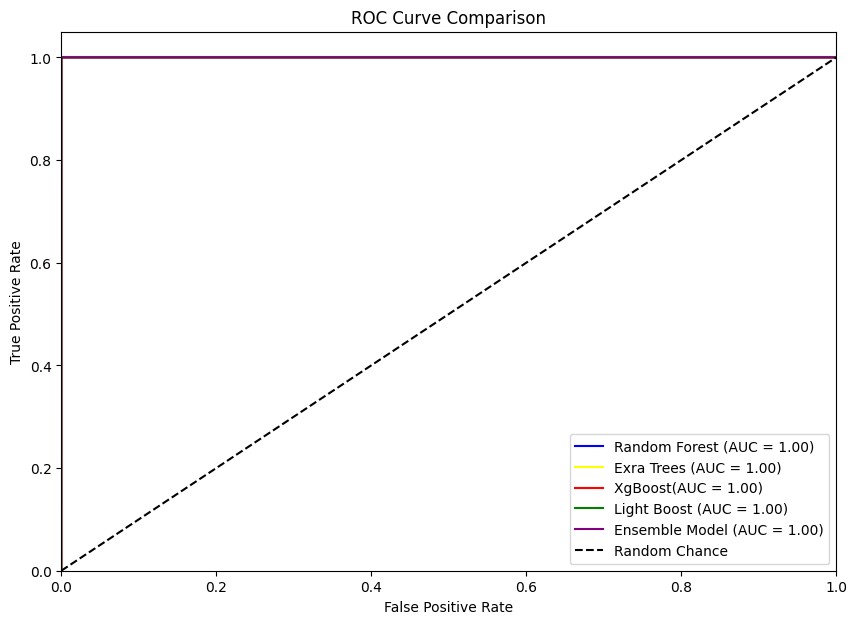

In [94]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Calculate ROC curves and AUC for each model
fpr_rf, tpr_rf, _ = roc_curve(y1_test, rf_model.predict_proba(X1_test)[:, 1])
fpr_et, tpr_et, _ = roc_curve(y2_test, et_model.predict_proba(X2_test)[:, 1])
fpr_xgb, tpr_xgb, _ = roc_curve(y3_test, xgb_model.predict_proba(X3_test)[:, 1])
fpr_lgb, tpr_lgb, _ = roc_curve(y4_test, lgb_model.predict_proba(X4_test)[:, 1])
voting_fpr, voting_tpr, _ = roc_curve(Y_test, voting_clf.predict_proba(X_test)[:, 1])


auc_rf = auc(fpr_rf, tpr_rf)
auc_et = auc(fpr_et, tpr_et)
auc_xgb = auc(fpr_xgb, tpr_xgb)
auc_lgb = auc(fpr_lgb, tpr_lgb)
voting_auc = auc(voting_fpr, voting_tpr)

# Plotting ROC Curves
plt.figure(figsize=(10, 7))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})', color='blue')
plt.plot(fpr_et, tpr_et, label=f'Exra Trees (AUC = {auc_et:.2f})', color='yellow')
plt.plot(fpr_xgb, tpr_xgb, label=f'XgBoost(AUC = {auc_xgb:.2f})', color='red')
plt.plot(fpr_lgb, tpr_lgb, label=f'Light Boost (AUC = {auc_lgb:.2f})', color='green')
plt.plot(voting_fpr, voting_tpr, label=f'Ensemble Model (AUC = {voting_auc:.2f})', color='purple')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.show()

## Soft Voting

In [95]:
from sklearn.ensemble import VotingClassifier

# Instantiate the Voting Classifier with soft voting
voting_clf = VotingClassifier(
    estimators=[
        ('rf', rf_model),
        ('et', et_model),
        ('xgb', xgb_model),
        ('lgb', lgb_model)
    ],
    voting='soft'  # Use soft voting
)

In [96]:
import pandas as pd

# Convert categorical columns to one-hot encoded columns
X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)

# Align columns between train and test sets (important to handle potential discrepancies)
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

In [97]:
# Fit the Voting Classifier on the training data
# Fit the Voting Classifier on the encoded training data
voting_clf.fit(X_train_encoded, Y_train)

[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Info] Number of positive: 316035, number of negative: 1534910
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.093384 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 841
[LightGBM] [Info] Number of data points in the train set: 1850945, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.170743 -> initscore=-1.580374
[LightGBM] [Info] Start training from score -1.580374


VotingClassifier(estimators=[('rf', RandomForestClassifier(random_state=40)),
                             ('et', ExtraTreesClassifier(random_state=40)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric='logloss',
                                            feature_typ...
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=None, n_jobs=None,
                                            num_parallel_tree=None,
                                            random_state=40, ...)),
                             ('lgb',
                              LGBMClassifier(eval_metric='logloss',
                                             random_state=40))],
                 voting='soft')

In [98]:
# Make predictions on the encoded test data
voting_predictions = voting_clf.predict(X_test_encoded)

[LightGBM] [Warning] Unknown parameter: eval_metric


In [99]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Calculate accuracy
accuracy = accuracy_score(Y_test, voting_predictions)
print(f"Ensemble Model Accuracy: {accuracy}")

# Print confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(Y_test, voting_predictions))

# Print classification report
print("Classification Report:")
print(classification_report(Y_test, voting_predictions))

Ensemble Model Accuracy: 0.9999589399594154
Confusion Matrix:
[[383755      8]
 [    11  78963]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    383763
           1       1.00      1.00      1.00     78974

    accuracy                           1.00    462737
   macro avg       1.00      1.00      1.00    462737
weighted avg       1.00      1.00      1.00    462737



[LightGBM] [Warning] Unknown parameter: eval_metric


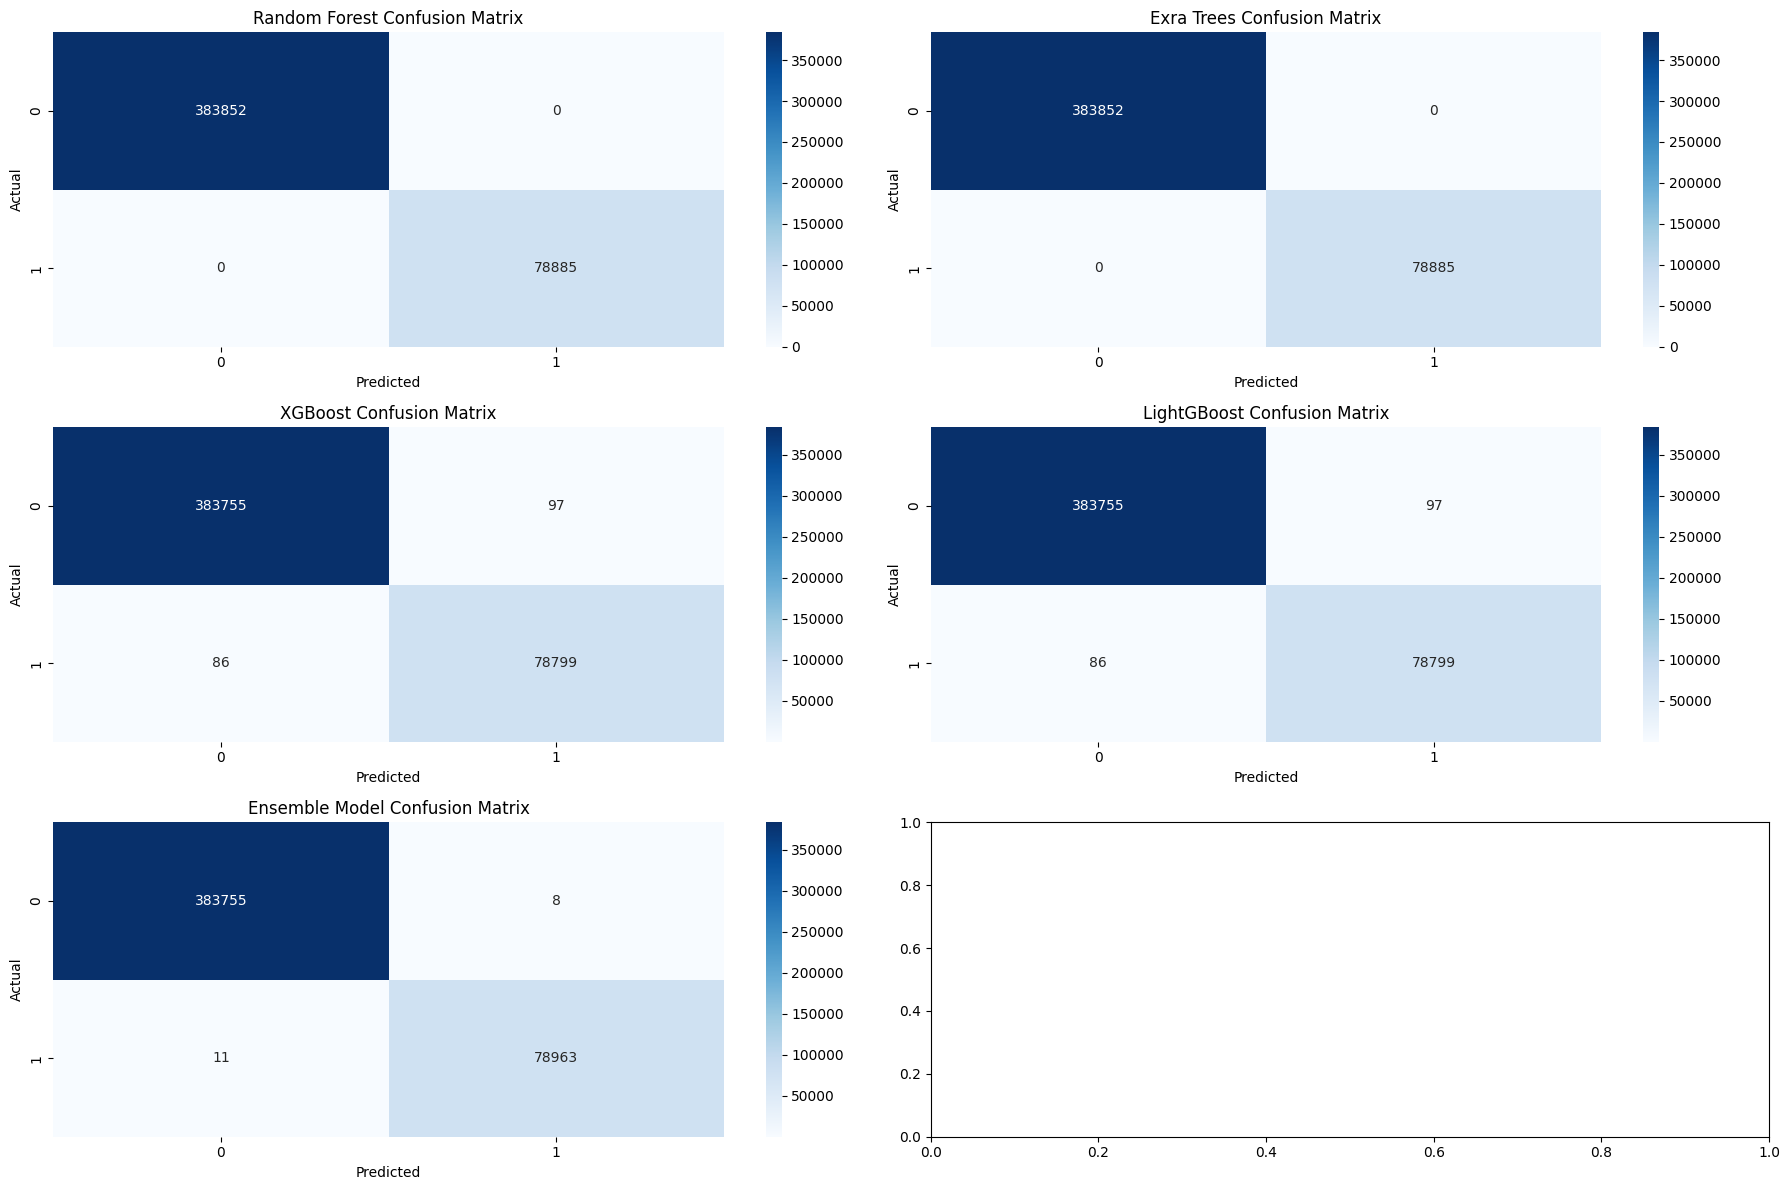

In [100]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_rf = confusion_matrix(y1_test, rf_model.predict(X1_test))
cm_et = confusion_matrix(y2_test, rf_model.predict(X2_test))
cm_xgb = confusion_matrix(y3_test, xgb_model.predict(X3_test))
cm_lgb = confusion_matrix(y4_test, xgb_model.predict(X4_test))
voting_cm = confusion_matrix(Y_test, voting_clf.predict(X_test_encoded))

# Plot confusion matrices
fig, axes = plt.subplots(3, 2, figsize=(18, 12))

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0])
axes[0, 0].set_title('Random Forest Confusion Matrix')
axes[0, 0].set_xlabel('Predicted')
axes[0, 0].set_ylabel('Actual')

sns.heatmap(cm_et, annot=True, fmt='d', cmap='Blues', ax=axes[0, 1])
axes[0, 1].set_title('Exra Trees Confusion Matrix')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('Actual')

sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', ax=axes[1, 0])
axes[1, 0].set_title('XGBoost Confusion Matrix')
axes[1, 0].set_xlabel('Predicted')
axes[1, 0].set_ylabel('Actual')

sns.heatmap(cm_lgb, annot=True, fmt='d', cmap='Blues', ax=axes[1, 1])
axes[1, 1].set_title('LightGBoost Confusion Matrix')
axes[1, 1].set_xlabel('Predicted')
axes[1, 1].set_ylabel('Actual')

sns.heatmap(voting_cm, annot=True, fmt='d', cmap='Blues', ax=axes[2, 0])
axes[2, 0].set_title('Ensemble Model Confusion Matrix')
axes[2, 0].set_xlabel('Predicted')
axes[2, 0].set_ylabel('Actual')

plt.tight_layout()
plt.show()

[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric


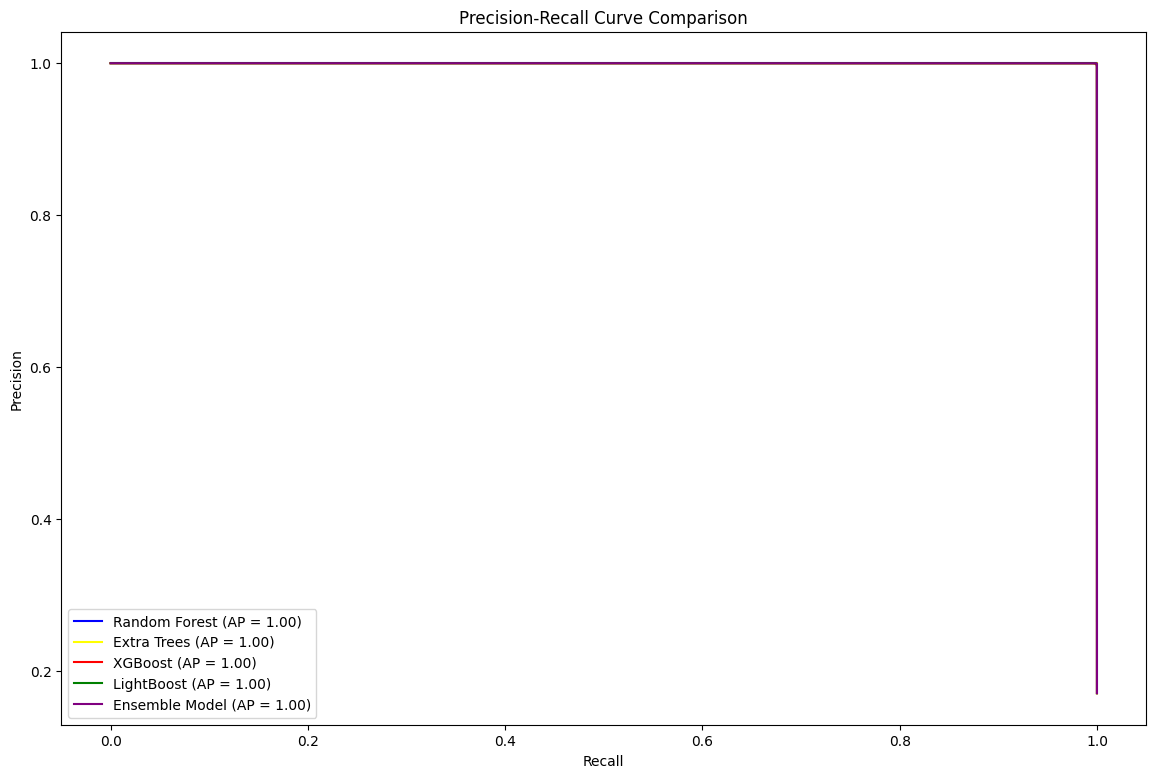

In [101]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate Precision-Recall curves and AUC for each model
precision_rf, recall_rf, _ = precision_recall_curve(y1_test, rf_model.predict_proba(X1_test)[:, 1])
precision_et, recall_et, _ = precision_recall_curve(y2_test, et_model.predict_proba(X2_test)[:, 1])
precision_xgb, recall_xgb, _ = precision_recall_curve(y3_test, xgb_model.predict_proba(X3_test)[:, 1])
precision_lgb, recall_lgb, _ = precision_recall_curve(y4_test, lgb_model.predict_proba(X4_test)[:, 1])
voting_precision, voting_recall, _ = precision_recall_curve(Y_test, voting_clf.predict_proba(X_test_encoded)[:, 1])

avg_precision_rf = average_precision_score(y1_test, rf_model.predict_proba(X1_test)[:, 1])
avg_precision_et = average_precision_score(y2_test, et_model.predict_proba(X2_test)[:, 1])
avg_precision_xgb = average_precision_score(y3_test, xgb_model.predict_proba(X3_test)[:, 1])
avg_precision_lgb = average_precision_score(y4_test, lgb_model.predict_proba(X4_test)[:, 1])
voting_avg_precision = average_precision_score(Y_test, voting_clf.predict_proba(X_test_encoded)[:, 1])

# Plotting Precision-Recall Curves
plt.figure(figsize=(14, 9))
plt.plot(recall_rf, precision_rf, label=f'Random Forest (AP = {avg_precision_rf:.2f})', color='blue')
plt.plot(recall_et, precision_et, label=f'Extra Trees (AP = {avg_precision_et:.2f})', color='yellow')
plt.plot(recall_xgb, precision_xgb, label=f'XGBoost (AP = {avg_precision_xgb:.2f})', color='red')
plt.plot(recall_lgb, precision_lgb, label=f'LightBoost (AP = {avg_precision_lgb:.2f})', color='green')
plt.plot(voting_recall, voting_precision, label=f'Ensemble Model (AP = {voting_avg_precision:.2f})', color='purple')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend(loc='lower left')
plt.show()

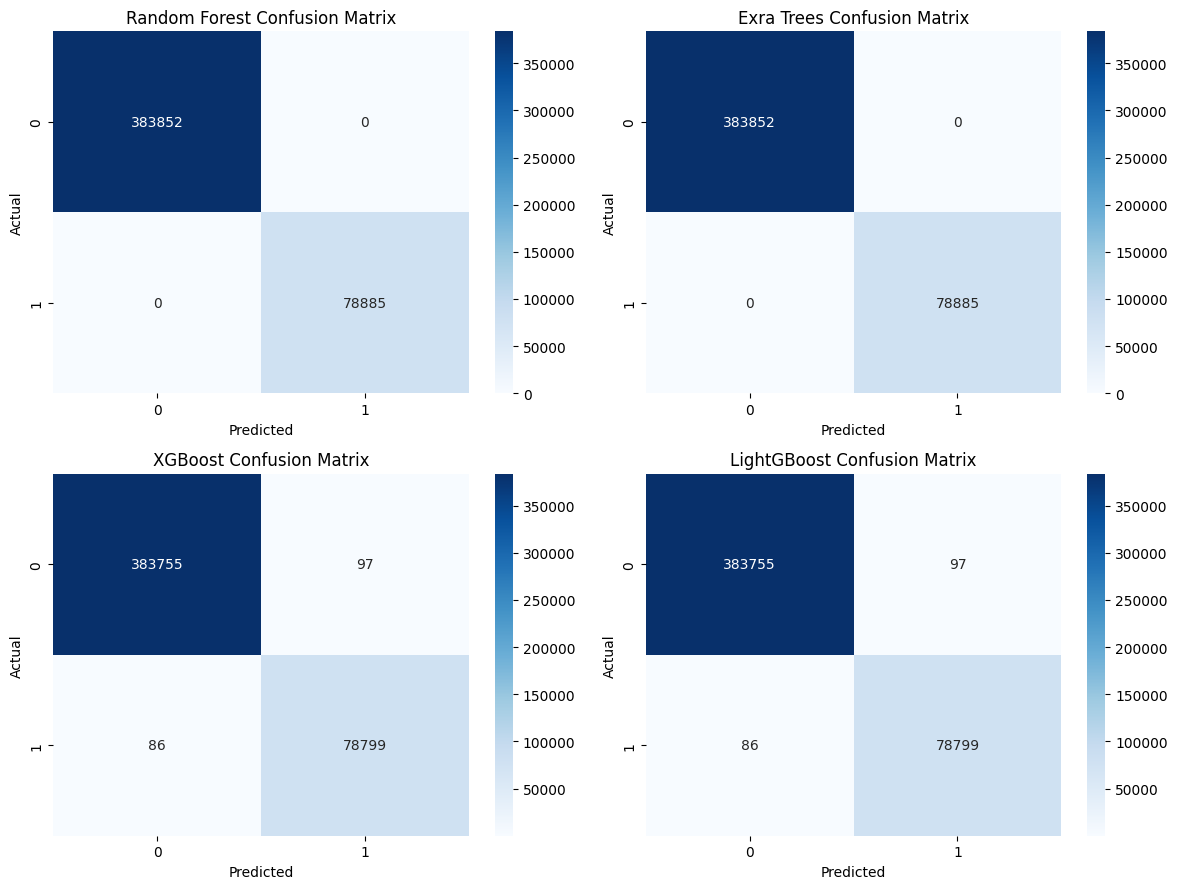

In [110]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_rf = confusion_matrix(y1_test, rf_model.predict(X1_test))
cm_et = confusion_matrix(y2_test, rf_model.predict(X2_test))
cm_xgb = confusion_matrix(y3_test, xgb_model.predict(X3_test))
cm_lgb = confusion_matrix(y4_test, xgb_model.predict(X4_test))

# Plot confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0])
axes[0, 0].set_title('Random Forest Confusion Matrix')
axes[0, 0].set_xlabel('Predicted')
axes[0, 0].set_ylabel('Actual')

sns.heatmap(cm_et, annot=True, fmt='d', cmap='Blues', ax=axes[0, 1])
axes[0, 1].set_title('Exra Trees Confusion Matrix')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('Actual')

sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', ax=axes[1, 0])
axes[1, 0].set_title('XGBoost Confusion Matrix')
axes[1, 0].set_xlabel('Predicted')
axes[1, 0].set_ylabel('Actual')

sns.heatmap(cm_lgb, annot=True, fmt='d', cmap='Blues', ax=axes[1, 1])
axes[1, 1].set_title('LightGBoost Confusion Matrix')
axes[1, 1].set_xlabel('Predicted')
axes[1, 1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
voting_cm = confusion_matrix(Y_test, voting_clf.predict(X_test_encoded))


# Make predictions (LGBMClassifier returns probabilities by default)
predictions_lgb = lgb_model.predict(X_test)
predictions_lgb = (predictions_lgb > 0.5).astype(int)

# Compute the confusion matrix
cm_lgb = confusion_matrix(y4_test, predictions_lgb)

# Plot the heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(voting_cm, annot=True, fmt='d', cmap='Blues', ax=axes[2, 0])


# Show the plot
plt.show()


sns.heatmap(voting_cm, annot=True, fmt='d', cmap='Blues', ax=axes[2, 0])
axes[2, 0].set_title('Ensemble Model Confusion Matrix')
axes[2, 0].set_xlabel('Predicted')
axes[2, 0].set_ylabel('Actual')

plt.tight_layout()
plt.show()

[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric


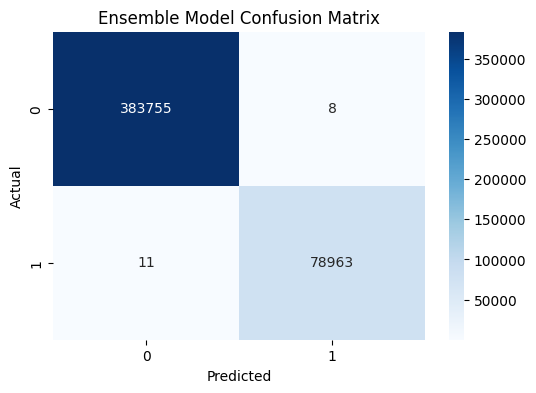

In [111]:
# Make predictions on the encoded test data
voting_predictions = voting_clf.predict(X_test_encoded)

# Compute the confusion matrix
voting_cm = confusion_matrix(Y_test, voting_clf.predict(X_test_encoded))

# Plot the heatmap
plt.figure(figsize=(6, 4))
ax = sns.heatmap(voting_cm, annot=True, fmt='d', cmap='Blues')

# Add labels and title
ax.set_title('Ensemble Model Confusion Matrix')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')

# Show the plot
plt.show()


In [112]:
# Imports (make sure this is at the top)
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
# Define individual models
rf_model = RandomForestClassifier(random_state=40)
et_model = ExtraTreesClassifier(random_state=40)
xgb_model = XGBClassifier(eval_metric='logloss', random_state=40)
lgb_model = LGBMClassifier(eval_metric='logloss', random_state=40) 

# Create a Voting Classifier with hard voting
hard_voting_clf = VotingClassifier(
    estimators=[
        ('rf', rf_model),
        ('et', et_model),
        ('xgb', xgb_model),
        ('lgb', lgb_model)
    ],
    voting='hard'
)

# Fit the Voting Classifier
hard_voting_clf.fit(X_train, Y_train)

# Make predictions
hard_voting_predictions = hard_voting_clf.predict(X_test)

[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Info] Number of positive: 316035, number of negative: 1534910
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.084651 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 841
[LightGBM] [Info] Number of data points in the train set: 1850945, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.170743 -> initscore=-1.580374
[LightGBM] [Info] Start training from score -1.580374
[LightGBM] [Warning] Unknown parameter: eval_metric


[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] Unknown parameter: eval_metric


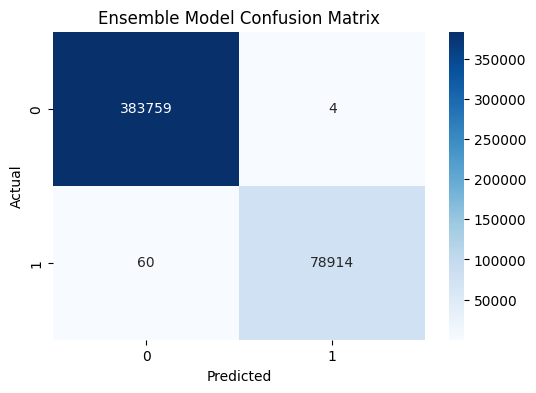

In [113]:
# Make predictions on the encoded test data
hard_voting_predictions = hard_voting_clf.predict(X_test)

# Compute the confusion matrix
hard_voting_cm = confusion_matrix(Y_test, hard_voting_clf.predict(X_test))

# Plot the heatmap
plt.figure(figsize=(6, 4))
ax = sns.heatmap(hard_voting_cm, annot=True, fmt='d', cmap='Blues')

# Add labels and title
ax.set_title('Ensemble Model Confusion Matrix')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')

# Show the plot
plt.show()
